# PDFT Calculation for H$_2$

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

Since one fragment has a neutral F atom whose ground state is 3-fold degenarate due to an unpaired electron in the _2p_ orbital (can be either in px, py and pz), we need to consider these possibilities through a "_configuration_" ensemble. _f4b_ handles this by specifying the atom, the orbital where the unpaired electron is and the initial ensemble weight. The later is optimized during the SCF loop.  

In [2]:
NHY = 0.8
STATES = [(("F 2p" + k, "beta", 0.0),) for k in "xyz"]

def hf_mol(sep=1.733, basis="6-31g", nhy=NHY):
    mol = fgto.M(atom=f"""
                F {-0.5*sep} 0 0
                H {+0.5*sep} 0 0
            """, unit="bohr", basis=basis, fragments={0: [0], 1: [1]},
                ensembles={"charge": {0: {"charges": (0, -1), "weights": (nhy, 1 - nhy), "spins": (1, 0)},
                                      1: {"charges": (0, 1), "weights": (nhy, 1 - nhy), "spins": (1, 0)}},
                        "config": {0: {"charge": 0, "states": STATES}},
                        "spin": [0, 1]})
    return mol

In [3]:
# define geometry
sep = 1.733
mol = hf_mol(basis='cc-pvdz')

my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

Eref = -100.33517559


---
## Do PDFT Calculations

### Inversion Method

In [4]:
mf1 = pdft.RKS(mol, method='inversion', maxiter=50)
mf1.kernel()
E_mf1, Df_mf1 = mf1.e_tot, mf1.make_rdm1()
nf_mf1 = D2n(Df_mf1[0]+Df_mf1[1], phi)

dE_mf1 = abs(Eref-E_mf1)
L1_mf1 = np.sum(np.abs(nf_mf1-nref)*w)
Nf_mf1 = np.sum(nf_mf1*w)
print(f"Energy difference (Ha): {dE_mf1:.3e}, Density error: {L1_mf1:.3e}")

P-DFT method=inversion xc=PBE fxc=PBE nao=19 grid=98920
  it    1  Ef =  -100.0379016255  dEf =         nan  |dVp| = 1.284e+00  omega = [0.3219 0.     0.6781]
  it    2  Ef =  -100.0224630449  dEf =   1.544e-02  |dVp| = 1.696e+00  omega = [0. 0. 1.]
  it    3  Ef =   -99.9733922068  dEf =   4.907e-02  |dVp| = 1.584e+00  omega = [8.3361e-19 1.6320e-01 8.3680e-01]
  it    4  Ef =   -99.9855240904  dEf =  -1.213e-02  |dVp| = 1.545e+00  omega = [1.6858e-17 1.1102e-16 1.0000e+00]
  it    5  Ef =   -99.9317852932  dEf =   5.374e-02  |dVp| = 1.367e+00  omega = [3.1689e-19 2.4839e-01 7.5161e-01]
  it    6  Ef =   -99.9518749145  dEf =  -2.009e-02  |dVp| = 1.240e+00  omega = [0.7672 0.0072 0.2256]
  it    7  Ef =   -99.9392927570  dEf =   1.258e-02  |dVp| = 1.160e+00  omega = [8.1169e-01 3.4590e-20 1.8831e-01]
  it    8  Ef =   -99.9260207261  dEf =   1.327e-02  |dVp| = 1.085e+00  omega = [8.4568e-01 3.7638e-18 1.5432e-01]
  it    9  Ef =   -99.9125319956  dEf =   1.349e-02  |dVp| = 1.017e+00  

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 50 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


### Reference Method

In [5]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=60)
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

P-DFT method=reference xc=PBE fxc=PBE nao=19 grid=98920
  it    1  Ef =  -100.0373551168  dEf =         nan  |dVp| = 9.461e-02  L1 = 5.525e-01  omega = [0.6582 0.1709 0.1709]
  it    2  Ef =  -100.0363335030  dEf =   1.022e-03  |dVp| = 7.967e-02  L1 = 5.083e-01  omega = [0.6685 0.1657 0.1657]
  it    3  Ef =  -100.0342430781  dEf =   2.090e-03  |dVp| = 6.849e-02  L1 = 4.763e-01  omega = [0.6787 0.1607 0.1607]
  it    4  Ef =  -100.0317957271  dEf =   2.447e-03  |dVp| = 5.963e-02  L1 = 4.513e-01  omega = [0.6853 0.1574 0.1574]
  it    5  Ef =  -100.0292643494  dEf =   2.531e-03  |dVp| = 5.258e-02  L1 = 4.306e-01  omega = [0.6921 0.1539 0.1539]
  it    6  Ef =  -100.0267697980  dEf =   2.495e-03  |dVp| = 4.678e-02  L1 = 4.133e-01  omega = [0.6967 0.1517 0.1517]
  it    7  Ef =  -100.0243675708  dEf =   2.402e-03  |dVp| = 4.205e-02  L1 = 3.983e-01  omega = [0.7012 0.1494 0.1494]
  it    8  Ef =  -100.0220798912  dEf =   2.288e-03  |dVp| = 3.791e-02  L1 = 3.852e-01  omega = [0.701  0.1495 

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 60 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


---
## Plot densities and partition potential

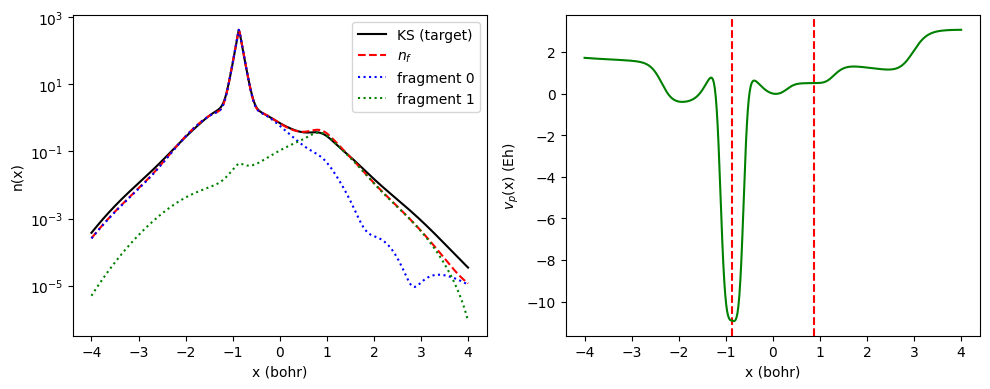

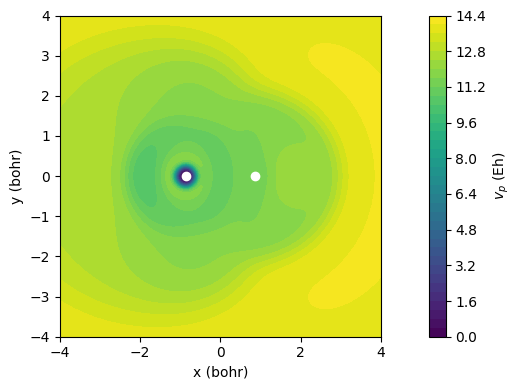

In [7]:
# # 1D plot along molecular axis
x = np.linspace(-4, 4, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf1.eval_density(line)                    # promolecular density
n_0 = mf1.eval_density(line, frag=0)            # fragment densities
n_1 = mf1.eval_density(line, frag=1)
vp  = mf1.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
ax[0].semilogy(x, n_0, 'b:', label='fragment 0')
ax[0].semilogy(x, n_1, 'g:', label='fragment 1')
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-4, 4, 160); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf1.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()